# RLS: adaptive vs tile channel selection in real data

In [1]:
import wasabi.rls, importlib
importlib.reload(wasabi.rls)

<module 'wasabi.rls' from '/home/bryan/Documents/workspace/WASABI/src/wasabi/rls.py'>

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from wasabi.data_simulation import make_ground_truth_params
from wasabi.utils import make_toeplitz_V, effective_stim_input
from wasabi.rls import (
    make_multistep_M,
    truncated_projector,
    run_selection,
)

# Load data

In [3]:
from pathlib import Path
PERI_ROOT = Path("//home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Nike/20251203_NRR_RW011/results/checkpoints/PeriStim")
TARGET = "target_A"
CONTROL_PERI_ROOT  = PERI_ROOT / "control_reaches" / TARGET
STIM_PERI_ROOT  = PERI_ROOT / "stim_reaches" / TARGET

In [4]:
include_8_contig = [12, 13, 14, 15, 16, 17, 18, 19, 20, 21]

control_files = sorted(CONTROL_PERI_ROOT.glob("peristim__*.npz"))
stim_files = sorted(file for br_num in include_8_contig for file in STIM_PERI_ROOT.glob(f"*BR_{br_num:03d}_*.npz"))

# Fit on control first

In [5]:
control_counts = np.load(control_files[0], allow_pickle=True)['NPRW_counts']
control_rel_t = np.load(control_files[0])['NPRW_rel_t']

In [6]:
np.load(control_files[0]).files

['sess',
 'br_idx',
 'overall_title',
 'meta',
 'ua_meta',
 'nprw_meta',
 'meta_json',
 'ua_meta_json',
 'nprw_meta_json',
 'align_meta_raw',
 'event_ms',
 'trial_labels',
 'trial_labels_all',
 'raw_trial_indices',
 'n_beh',
 'beh_rel_t',
 'beh_cam0_pos_med',
 'beh_cam1_pos_med',
 'beh_cam0_vel_med',
 'beh_cam1_vel_med',
 'beh_cam0_segs',
 'beh_cam1_segs',
 'beh_cam0_vel_segs',
 'beh_cam1_vel_segs',
 'beh_cam0_names',
 'beh_cam1_names',
 'hr_sig',
 'vog_sig',
 'ts_state_rel_t',
 'ts_state_segs',
 'ts_state_char_segs',
 'ts_state_char',
 'ts_state_num',
 'n_ts_state_trials',
 'NPRW_med',
 'NPRW_var',
 'NPRW_med_counts',
 'NPRW_rates_hz',
 'NPRW_rates_zeroed',
 'NPRW_counts',
 'NPRW_width_ms',
 'NPRW_rel_t',
 'NPRW_peak_ms_dedup',
 'NPRW_amps_ms_dedup',
 'HAS_BR',
 'UA_med',
 'UA_var',
 'UA_med_counts',
 'UA_rates_hz',
 'UA_rates_zeroed',
 'UA_counts',
 'UA_width_ms',
 'UA_rel_t',
 'UA_peak_ms_dedup',
 'UA_amps_ms_dedup',
 'ua_ids_1based',
 'ua_region',
 'ua_region_names',
 'ua_port',
 '

In [7]:
control_counts.shape, control_rel_t.shape

((13, 128, 70), (70,))

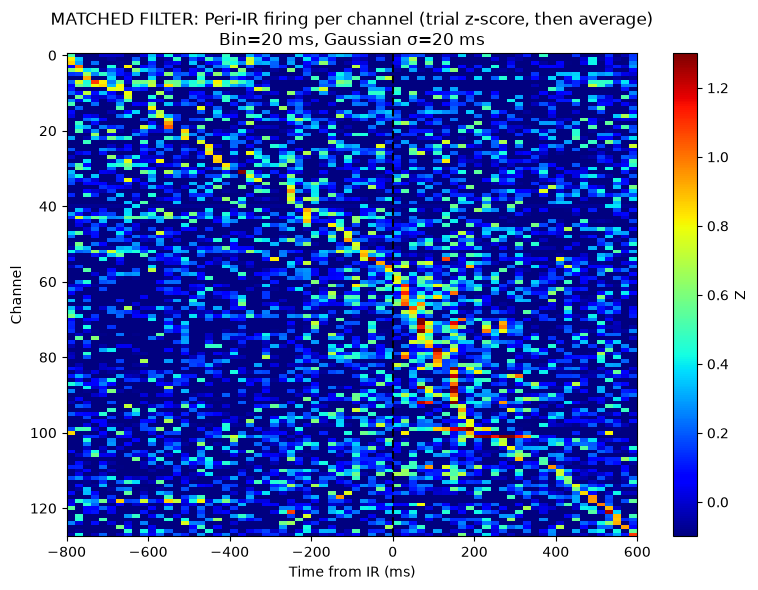

In [8]:
BIN_MS = 20
SIGMA_MS = 20
# z score per trial
mu = np.nanmean(control_counts[:, :, :], axis=2, keepdims=True)
sig = np.nanstd (control_counts[:, :, :], axis=2, keepdims=True)
sig = np.clip(sig, 1e-6, None)
counts_z = (control_counts - mu) / sig
psth_z = np.nanmean(counts_z, axis=0)
X = psth_z
t = control_rel_t

# Peak value and peak time (argmax) within the search window
X_finite = np.where(np.isfinite(X), X, -np.inf)
peak_idx = np.argmax(X_finite, axis=1)
peak_time_ms = t[peak_idx]
peak_val = np.max(X_finite, axis=1)

# Keep only neurons with a real response; rest go to bottom
z_thresh = 0  # tune (0.5–1.5 is common)
responsive = np.isfinite(peak_val) & (peak_val >= z_thresh)

order_resp = np.argsort(peak_time_ms[responsive])  # earliest first
order = np.concatenate([np.where(responsive)[0][order_resp],
                        np.where(~responsive)[0]])

psth_ch_sorted = psth_z[order]

fig, ax = plt.subplots(figsize=(8, 6))
ax.set_facecolor("0.5")
pc = ax.pcolormesh(
    control_rel_t,
    np.arange(psth_ch_sorted.shape[0]),
    psth_ch_sorted,
    shading="nearest",
    cmap="jet",
    vmin=-0.1,
    vmax=1.3,
)

ax.invert_yaxis()
ax.axvline(0, linestyle="--", color="black")
ax.set_xlabel("Time from IR (ms)")
ax.set_ylabel("Channel")
ax.set_title(f"MATCHED FILTER: Peri-IR firing per channel (trial z-score, then average)\nBin={BIN_MS} ms, Gaussian σ={SIGMA_MS} ms")
fig.colorbar(pc, ax=ax, label="Z")
plt.tight_layout()
plt.show()

In [9]:
import jax.numpy as jnp
import jax.random as jr
import optax
from jax import value_and_grad, jit
from functools import partial

from wasabi.plds_fit import loss_fn, run_smoother, alignment  # module holding model_fns/loss_fn
from wasabi.utils import softplus_jnp

from dynamax.utils.utils import random_rotation

In [10]:
key = jr.key(0)
key1, key2 = jr.split(key, 2)

all_observations_control = jnp.array(control_counts.transpose(0, 2, 1))
num_trials, num_timesteps, n_ch = all_observations_control.shape
state_dim = 4

inputs_control = jnp.zeros((num_trials, num_timesteps, n_ch))

# keep[t] False where any channel is blanked/NaN
keep_control = jnp.all(jnp.isfinite(all_observations_control), axis=2)
observations_control = jnp.nan_to_num(all_observations_control)

In [11]:
BETA_STIM = 1.0
BETA_EMIT = 1.0
B_SCALE = 1.0
Q_dyn = 1e-3 * jnp.eye(state_dim)
V = jnp.eye(n_ch)  # irrelevant here: control inputs are zero

def inv_softplus(y, beta):
    return y + jnp.log1p(-jnp.exp(-beta * y)) / beta

C_init = 0.5 * jr.normal(key2, shape=(n_ch, state_dim))
mean_rate = jnp.mean(observations_control, axis=(0, 1))
d_init = inv_softplus(jnp.clip(mean_rate, 1e-3), BETA_EMIT)
A_init = jnp.eye(state_dim)
B_init = 0.01 * jr.normal(key1, shape=(state_dim, n_ch))
b_init = jnp.array(0.0)

theta = (C_init, d_init, A_init, B_init, b_init)

fit_loss = partial(loss_fn, Q_dyn=Q_dyn, V=V, B_SCALE=B_SCALE,
                   BETA_STIM=BETA_STIM, BETA_EMIT=BETA_EMIT)

optimizer = optax.adam(5e-3)
opt_state = optimizer.init(theta)

@jit
def step(theta, opt_state, observations, inputs, keep):
    loss, grads = value_and_grad(fit_loss)(theta, observations, inputs, keep)
    updates, new_opt_state = optimizer.update(grads, opt_state)
    return optax.apply_updates(theta, updates), new_opt_state, loss

losses = []
for epoch in range(500):
    theta, opt_state, loss = step(theta, opt_state, observations_control,
                                  inputs_control, keep_control)
    losses.append(float(loss))
    if epoch % 50 == 0:
        print(f"epoch {epoch:4d}  loss={loss:.2f}  sigma_max(A)={jnp.linalg.norm(theta[2], ord=2):.4f}")

C_fit, d_fit, A_fit, B_fit, b_fit = theta
print('singular values of A_fit:', jnp.linalg.svd(A_fit, compute_uv=False))

epoch    0  loss=55422.95  sigma_max(A)=1.0062
epoch   50  loss=54943.15  sigma_max(A)=1.1139
epoch  100  loss=54490.41  sigma_max(A)=1.1678
epoch  150  loss=54288.19  sigma_max(A)=1.1616
epoch  200  loss=54207.07  sigma_max(A)=1.2263
epoch  250  loss=54151.35  sigma_max(A)=1.2824
epoch  300  loss=54100.35  sigma_max(A)=1.3341
epoch  350  loss=54057.01  sigma_max(A)=1.3799
epoch  400  loss=54026.48  sigma_max(A)=1.3972
epoch  450  loss=54005.34  sigma_max(A)=1.3885
singular values of A_fit: [1.372919   1.0259778  0.99075043 0.6601013 ]


In [12]:
posts_control = run_smoother(theta, observations_control, inputs_control,
                             keep_control, Q_dyn, V, B_SCALE, BETA_STIM, BETA_EMIT)

recon_control = softplus_jnp(posts_control.smoothed_means @ C_fit.T + d_fit, BETA_EMIT)
innovations_control = observations_control - recon_control

U, S, Vt = jnp.linalg.svd(C_fit, full_matrices=False)
R = Vt.T
z_control = posts_control.smoothed_means @ R

## Plots

In [13]:
import plotly.graph_objects as go
import nbformat
import plotly.io._renderers as _r
_r.nbformat = nbformat

def plot_latent_phase_portrait(conditions, alpha_trials=0.15, title=None, colorscale="Turbo"):
    """conditions: list of (label, z, centers_ms, color_or_groups)

    If the 4th element is an array of length n_trials, trials are split by
    group and one mean trace is drawn per group. Otherwise it's a color string.
    """
    import plotly.colors as pc

    fig = go.Figure()
    single = len(conditions) == 1

    for label, z, centers_ms, spec in conditions:
        z = np.asarray(z)[:, :, :3]
        ir = int(np.argmin(np.abs(centers_ms)))

        if np.ndim(spec) == 0:
            groups = np.zeros(z.shape[0], dtype=int)
            names = [label]
            colors = [spec]
        else:
            groups = np.asarray(spec)
            uniq = np.unique(groups)
            groups = np.searchsorted(uniq, groups)
            names = [f"{label} {g}" for g in uniq]
            colors = pc.sample_colorscale(colorscale, np.linspace(0, 1, len(uniq)))

        for g, (name, color) in enumerate(zip(names, colors)):
            zg = z[groups == g]

            sep = np.full((zg.shape[0], 1, 3), np.nan)
            flat = np.concatenate([zg, sep], axis=1).reshape(-1, 3)
            fig.add_trace(go.Scatter3d(
                x=flat[:, 0], y=flat[:, 1], z=flat[:, 2],
                mode="lines", line=dict(color=color, width=1),
                opacity=alpha_trials, showlegend=False,
            ))

            m = zg.mean(axis=0)
            x, y, zz = m[:, 0], m[:, 1], m[:, 2]

            fig.add_trace(go.Scatter3d(
                x=x, y=y, z=zz,
                mode="markers+lines",
                marker=dict(size=3, color=centers_ms, colorscale="Viridis",
                            showscale=False),
                line=dict(color=color, width=4),
                name=f"{name} mean",
            ))
            fig.add_trace(go.Scatter3d(
                x=[x[0]], y=[y[0]], z=[zz[0]],
                mode="markers", marker=dict(size=6, color="green"),
                name=f"{name} start",
            ))
            fig.add_trace(go.Scatter3d(
                x=[x[ir]], y=[y[ir]], z=[zz[ir]],
                mode="markers", marker=dict(size=6, color="yellow"),
                name=f"{name} IR",
            ))

    fig.update_layout(
        title=title or " vs ".join(c[0] for c in conditions) + " latent trajectories",
        scene=dict(xaxis_title="z₁", yaxis_title="z₂", zaxis_title="z₃", aspectmode="cube"),
        legend=dict(itemsizing="constant", x=1.05, y=0.5),
        margin=dict(l=0, r=0, b=0, t=40),
        width=1000, height=600,
    )
    return fig

fig = plot_latent_phase_portrait([("control", z_control, control_rel_t, "red")], alpha_trials=0.05)
fig.show()

# Batch fit on stim trials

In [14]:
import json

stim_rel_t_raw = np.load(stim_files[0])['NPRW_rel_t']

# The peristim extraction drops the blanked window rather than masking it,
# leaving a gap in the time axis. Reinsert it as NaN bins so every step is one bin.
step = float(np.median(np.diff(stim_rel_t_raw)))
gaps = np.diff(stim_rel_t_raw)
g = int(np.argmax(gaps))
n_insert = int(round(gaps[g] / step)) - 1
stim_rel_t = np.concatenate([
    stim_rel_t_raw[:g + 1],
    stim_rel_t_raw[g] + step * np.arange(1, n_insert + 1),
    stim_rel_t_raw[g + 1:],
])
n_bins_pad = len(stim_rel_t)

STIM_DUR_MS = 100.0  # confirm against nprw_meta_json
stim_bins = np.flatnonzero((stim_rel_t >= 0) & (stim_rel_t < STIM_DUR_MS))
ir_pre, ir_post = g, g + n_insert + 1

print(f"gap after {stim_rel_t_raw[g]:.0f} ms is {gaps[g]:.0f} ms -> inserted {n_insert} bins "
      f"(resumes at {stim_rel_t[ir_post]:.0f} vs actual {stim_rel_t_raw[g + 1]:.0f})")
print(f"stim spans bins {stim_bins}, pre={stim_rel_t[ir_pre]:.0f} post={stim_rel_t[ir_post]:.0f} ms")
print("control axis uniform:", bool(np.allclose(np.diff(control_rel_t), step)))

counts_list, inputs_list, s_rows = [], [], []
n_ch = None

for f in stim_files:
    npz = np.load(f, allow_pickle=True)
    counts = npz['NPRW_counts']                  # (trials, ch, bins)
    rel_t = npz['NPRW_rel_t']
    meta = json.loads(npz["nprw_meta_json"].item())
    ch0 = np.asarray(meta["stim_channels"], dtype=int) - 1

    n_tr, n_ch, n_bins = counts.shape
    if n_ch is None:
        n_ch = n_ch
    assert n_ch == n_ch, f"{f.name}: channel count mismatch"
    assert np.allclose(rel_t, stim_rel_t_raw), f"{f.name}: time axis mismatch"

    blank = np.full((n_tr, n_ch, n_insert), np.nan)
    counts_list.append(np.concatenate(
        [counts[:, :, :g + 1], blank, counts[:, :, g + 1:]], axis=2))

    s = np.zeros(n_ch)
    s[ch0] = 1.0
    u = np.zeros((n_tr, n_bins_pad, n_ch))
    u[np.ix_(np.arange(n_tr), stim_bins, ch0)] = 1.0

    inputs_list.append(u)
    s_rows.append(s)

# one spatial pattern per file, deduped and sorted by start channel
s_rows = np.stack(s_rows)
s_cand_real, block_to_cand = np.unique(s_rows, axis=0, return_inverse=True)
block_to_cand = np.asarray(block_to_cand).ravel()
order_asc = np.argsort([np.flatnonzero(s)[0] for s in s_cand_real])
s_cand_real = s_cand_real[order_asc]
block_to_cand = np.argsort(order_asc)[block_to_cand]

stim_counts = np.concatenate(counts_list, axis=0)
inputs_stim = jnp.array(np.concatenate(inputs_list, axis=0))

stim_block = np.repeat(np.arange(len(counts_list)), [c.shape[0] for c in counts_list])
cand_per_trial = block_to_cand[stim_block]

all_observations_stim = jnp.array(stim_counts.transpose(0, 2, 1))
n_trials_s, n_bins_s, n_ch_s = all_observations_stim.shape
keep_stim = jnp.all(jnp.isfinite(all_observations_stim), axis=2)
observations_stim = jnp.nan_to_num(all_observations_stim)

assert n_ch_s == n_ch
assert inputs_stim.shape == all_observations_stim.shape

print(f"{len(stim_files)} files -> {s_cand_real.shape[0]} distinct patterns")
print("channels per candidate:", [np.flatnonzero(s).tolist() for s in s_cand_real])
print("kept bins per trial:", int(keep_stim[0].sum()), "of", n_bins_pad)

gap after -30 ms is 159 ms -> inserted 7 bins (resumes at 129 vs actual 129)
stim spans bins [40 41 42 43 44], pre=-30 post=129 ms
control axis uniform: True
10 files -> 10 distinct patterns
channels per candidate: [[0, 1, 2, 3, 4, 5, 6, 7], [4, 5, 6, 7, 8, 9, 10, 11], [8, 9, 10, 11, 12, 13, 14, 15], [12, 13, 14, 15, 16, 17, 18, 19], [16, 17, 18, 19, 20, 21, 22, 23], [20, 21, 22, 23, 24, 25, 26, 27], [24, 25, 26, 27, 28, 29, 30, 31], [28, 29, 30, 31, 32, 33, 34, 35], [32, 33, 34, 35, 36, 37, 38, 39], [36, 37, 38, 39, 40, 41, 42, 43]]
kept bins per trial: 63 of 70


In [15]:
width = 3.0
V_stim = jnp.array(make_toeplitz_V(n_ch, width))

theta_stim = (C_fit, d_fit, A_fit,
              0.01 * jr.normal(jr.key(1), shape=(state_dim, n_ch)),
              jnp.array(0.0))

stim_loss = partial(loss_fn, Q_dyn=Q_dyn, V=V_stim, B_SCALE=B_SCALE,
                    BETA_STIM=BETA_STIM, BETA_EMIT=BETA_EMIT)

opt_stim = optax.adam(1e-3)
opt_state_stim = opt_stim.init(theta_stim)

@jit
def step_stim(theta, opt_state, observations, inputs, keep):
    loss, grads = value_and_grad(stim_loss)(theta, observations, inputs, keep)
    updates, new_state = opt_stim.update(grads, opt_state)
    return optax.apply_updates(theta, updates), new_state, loss

losses_stim = []
for epoch in range(500):
    theta_stim, opt_state_stim, loss = step_stim(theta_stim, opt_state_stim,
                                                 observations_stim, inputs_stim, keep_stim)
    losses_stim.append(float(loss))
    if epoch % 50 == 0:
        print(f"epoch {epoch:4d}  loss={loss:.2f}  |B|={jnp.linalg.norm(theta_stim[3]):.4f}  b={float(theta_stim[4]):.3f}")

C_fit_s, d_fit_s, A_fit_s, B_fit_s, b_fit_s = theta_stim
print('singular values of A_fit_s:', jnp.linalg.svd(A_fit_s, compute_uv=False))

epoch    0  loss=349546.47  |B|=0.2299  b=-0.001
epoch   50  loss=329440.34  |B|=0.3921  b=-0.015
epoch  100  loss=314695.16  |B|=0.4442  b=-0.003
epoch  150  loss=299843.22  |B|=0.5223  b=0.028
epoch  200  loss=283931.25  |B|=0.5715  b=0.051
epoch  250  loss=271385.00  |B|=0.5878  b=0.057
epoch  300  loss=265567.56  |B|=0.6129  b=0.063
epoch  350  loss=263380.12  |B|=0.6459  b=0.071
epoch  400  loss=262249.09  |B|=0.6654  b=0.074
epoch  450  loss=261384.44  |B|=0.6763  b=0.075
singular values of A_fit_s: [1.2465032  1.0384599  1.0006654  0.49369058]


In [16]:
posts_stim = run_smoother(theta_stim, observations_stim, inputs_stim, keep_stim,
                          Q_dyn, V_stim, B_SCALE, BETA_STIM, BETA_EMIT)

recon_stim = softplus_jnp(posts_stim.smoothed_means @ C_fit_s.T + d_fit_s, BETA_EMIT)
innovations_stim = observations_stim - recon_stim

rot, rot_inv = alignment(C_fit, C_fit_s)
z_stim = (posts_stim.smoothed_means @ rot) @ R

fig = plot_latent_phase_portrait(
    [("stim", z_stim, stim_rel_t, stim_block)],
    alpha_trials=0.03,
)
fig.show()

In [17]:
fig = plot_latent_phase_portrait(
    [("control", z_control, control_rel_t, "red"),
    ("stim", z_stim, stim_rel_t, stim_block)],
    alpha_trials=0.03,
)
fig.update_layout(scene_camera=dict(
    eye=dict(x=1.75, y=0.75, z=0.75),
    center=dict(x=0, y=0, z=-0.2),
))
fig.show()

# Fit via WASABI vs Tile (sequentially)

In [18]:
import numpy as np
from wasabi.rls import RowRLS, run_sequential, projected_error, get_perturbation_agg

K, N = state_dim, n_ch
horizon = ir_post - ir_pre

# perturbation across the blanked window
Z_all, R_all = get_perturbation_agg(
    posts_stim.smoothed_means, posts_stim.smoothed_covariances,
    A_fit_s, Q_dyn, ir_pre, ir_post,
) # in jax array
Z_all, R_all = np.asarray(Z_all), np.asarray(R_all)

U_cand = effective_stim_input(s_cand_real, np.asarray(V_stim), float(b_fit_s), BETA_STIM)
n_cand = U_cand.shape[0]
Pu_real, rank_real = truncated_projector(U_cand, energy=0.99)

print("blanked bins:", np.flatnonzero(~np.asarray(keep_stim)[0]))

# hold out a quarter of each pool for predictive error
rng = np.random.default_rng(0)
pools, test_parts = [], []
for j in range(n_cand):
    idx = rng.permutation(np.flatnonzero(cand_per_trial == j))
    n_test = max(1, len(idx) // 4)
    test_parts.append(idx[:n_test])
    pools.append(idx[n_test:].tolist())
test_idx = np.concatenate(test_parts)
print("pool sizes:", [len(p) for p in pools], "| held out:", len(test_idx))

# acquisition uses the pool-mean noise cov; the update uses the trial's own
R_cand = np.stack([R_all[cand_per_trial == j].mean(axis=0) for j in range(n_cand)])
prior_var = float((np.asarray(B_fit_s) ** 2).mean()) # use fitted B from control to get prior

# Ordering tiling
starts = np.array([np.flatnonzero(s)[0] for s in s_cand_real])
coarse = np.flatnonzero(starts % 8 == 0)
fine = np.flatnonzero(starts % 8 != 0)
tile_order = np.concatenate([coarse, fine])

def heldout_err(W):
    Z_hat = U_cand[cand_per_trial[test_idx]] @ W.T # Z^hat = U * B
    return float(np.linalg.norm(Z_hat - Z_all[test_idx]) / np.linalg.norm(Z_all[test_idx]))

def replay(mode, seed=0):
    rng = np.random.default_rng(seed)
    avail = [rng.permutation(pool).tolist() for pool in pools] # Randomly permute the available trials to feed into a selection of stim condition
    tracker = RowRLS(K, N, prior_var=prior_var)
    errs, lds, nis, order = [heldout_err(tracker.W)], [float(tracker.logdet())], [], []
    t = 0
    while any(avail):
        curr_cand_idx = [cand_idx for cand_idx in range(n_cand) if avail[cand_idx]] # 
        if mode == "D_opt":
            chosen_trial = max(curr_cand_idx, key=lambda k: tracker.info_gain(U_cand[k], R_cand[k]))
        elif mode == "tile":
            chosen_trial = curr_cand_idx[t % len(curr_cand_idx)]
        elif mode == "tile_coarse_fine":
            cyc = [k for k in tile_order if k in curr_cand_idx]
            chosen_trial = cyc[t % len(cyc)]
        else:
            chosen_trial = curr_cand_idx[rng.integers(len(curr_cand_idx))]
        i = avail[chosen_trial].pop() # remove this used trial from avail list
        nis_t, ld = run_sequential(tracker, U_cand[chosen_trial][None], Z_all[i][None], R_all[i][None])
        order.append(chosen_trial)
        nis.append(float(nis_t[0]))
        lds.append(float(ld[0]))
        errs.append(heldout_err(tracker.W))
        t += 1
    return map(np.asarray, (errs, lds, nis, order)), tracker

n_seeds = 20
MODES = ("D_opt", "tile_coarse_fine", "random")  # "tile",
curves, logdet, nis_all, selected, trackers = {}, {}, {}, {}, {}
for mode in MODES:
    e, l, ns, sel, tk = [], [], [], [], []
    for seed in range(n_seeds):
        (err, ld, nis_seed, order), tracker = replay(mode, seed)
        e.append(err); l.append(ld); ns.append(nis_seed); sel.append(order); tk.append(tracker)
    curves[mode], logdet[mode] = np.vstack(e), np.vstack(l)
    nis_all[mode], selected[mode] = np.vstack(ns), np.vstack(sel)
    trackers[mode] = tk
    pe = np.mean([projected_error(x.W, np.asarray(B_fit_s), U_cand) for x in tk])
    print(f"{mode}: heldout err {curves[mode][:, -1].mean():.4f}  "
          f"logdet drop {logdet[mode][:, 0].mean() - logdet[mode][:, -1].mean():.1f} nats  "
          f"NIS {nis_all[mode].mean():.2f} (target {K})  "
          f"vs batch B: {pe:.4f}")

blanked bins: [39 40 41 42 43 44 45]
pool sizes: [5, 3, 6, 6, 8, 7, 6, 3, 4, 5] | held out: 12
D_opt: heldout err 0.7207  logdet drop 17.2 nats  NIS 6.28 (target 4)  vs batch B: 0.7626
tile_coarse_fine: heldout err 0.7213  logdet drop 17.2 nats  NIS 6.30 (target 4)  vs batch B: 0.7591
random: heldout err 0.7206  logdet drop 17.2 nats  NIS 6.29 (target 4)  vs batch B: 0.7594


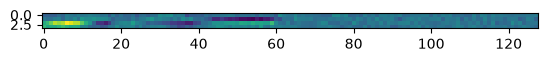

In [20]:
plt.imshow(B_fit_s)

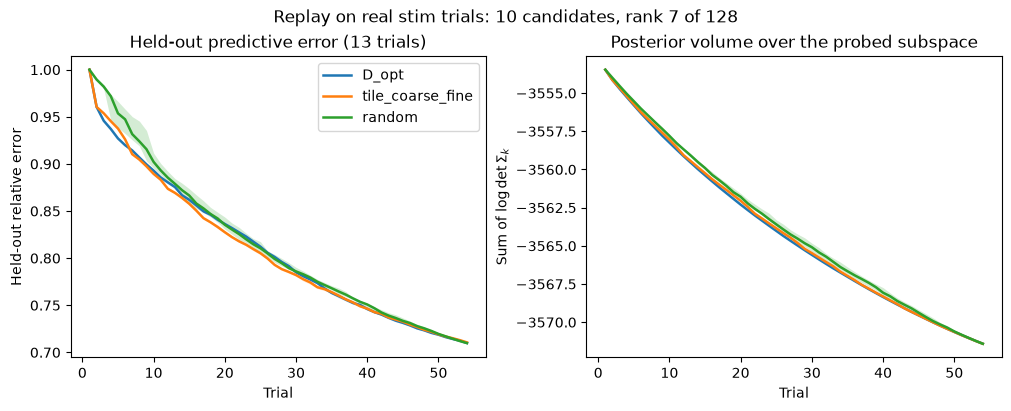

In [21]:
n_steps = curves["D_opt"].shape[1]
trials = np.arange(1, n_steps + 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)


for mode in MODES:
    for ax, data, ylab in (
        (axes[0], curves[mode], "Held-out relative error"),
        (axes[1], logdet[mode],     r"Sum of $\log\det \Sigma_k$"),
    ):
        lo, med, hi = np.percentile(data, [25, 50, 75], axis=0)
        line = ax.plot(trials, med, lw=1.8, label=mode)[0]
        ax.fill_between(trials, lo, hi, color=line.get_color(), alpha=0.2, lw=0)
        ax.set_xlabel("Trial")
        ax.set_ylabel(ylab)

axes[0].legend()
axes[0].set_title(f"Held-out predictive error ({len(test_idx)} trials)")
axes[1].set_title("Posterior volume over the probed subspace")
fig.suptitle(f"Replay on real stim trials: {n_cand} candidates, rank {rank_real} of {N}")
plt.show()

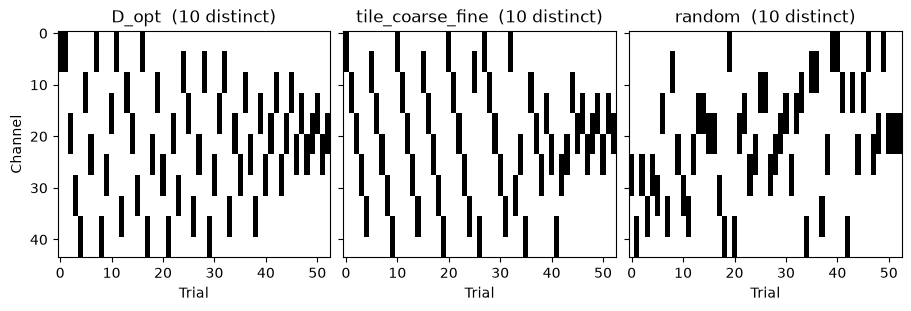

In [25]:
seed_show = 0
n_steps = selected["D_opt"].shape[1]

fig, axes = plt.subplots(1, len(MODES), figsize=(3 * len(MODES), 3),
                         constrained_layout=True, sharey=True)

for ax, mode in zip(axes, MODES):
    js = selected[mode][seed_show]

    # expand candidate index to its stim channels
    S_sel = s_cand_real[js]  # (n_steps, n_ch)
    ax.imshow(S_sel.T, aspect="auto", interpolation="nearest",
              vmin=0, vmax=1, cmap="Greys")
    ax.set_title(f"{mode}  ({len(np.unique(js))} distinct)")
    ax.set_xlabel("Trial")

axes[0].set_ylim(43.5, -0.5)
axes[0].set_ylabel("Channel")
plt.show()

## Ground truth

In [20]:

# Hyperparameters for the simulation
rng = np.random.default_rng(0)
K, N = 4, 128
w, b = 2.0, -0.5 # width and threshold
BETA_STIM = 5.0
B_SCALE = 5.0  # roughly the std of B_true; keeps B_true at unit scale relative to V

n_stim_ch, n_conditions, n_reps = 8, 10, 10
V = make_toeplitz_V(N, w)
B_true = B_SCALE * rng.standard_normal((K, N))

A_true = np.asarray(make_ground_truth_params(
    K=K, N=N, spectral_radius=0.9, sigma2_Q=0.2, sigma2_C=0.05, w=w, b_input=b,
    B_scale=B_SCALE, seed=0,
)["A"])

# Stim params
BIN_SIZE = 20.0
STIM_DUR = 100.0
n_stim_bins = int(round(STIM_DUR / BIN_SIZE))

# Correlated latent noise
L = rng.standard_normal((K, K))
R_fixed = L @ L.T + 0.4 * np.eye(K) # Make into PSD and add to eigenvalue

# Multi-step propagation over the stim window
M_step = make_multistep_M(A_true, horizon=n_stim_bins)

## Adaptive vs random selection over a candidate set

In [21]:
print("=" * 60)
print(f"Adaptive (D optimal) vs random selection, contiguous {n_stim_ch}-channel blocks")
print("=" * 60)

# Create candidate set: all 8-contiguous blocks (121)
s_cand = np.zeros((N - n_stim_ch + 1, N)) # 121 blocks
for j in range(N - n_stim_ch + 1):
    s_cand[j, j:j + n_stim_ch] = 1.0 # populate stim vectors (s) for each candidates
U_cand = effective_stim_input(s_cand, V, b, BETA_STIM)

Pu, rank = truncated_projector(U_cand, energy=0.99)
print(f"reachable dimensions: {rank} of {N}")

def pred_err_all(W):
    # Error over the full candidate set, which the tracker also trained on
    pred = U_cand @ W.T
    true = U_cand @ B_true.T
    return float(np.linalg.norm(pred - true) / np.linalg.norm(true))

for mode in ("D_opt", "tile", "random"):
    errs, logdets, sel_j, tracker, _ = run_selection(
        mode, 1000, s_cand, B_true, R_fixed,
        K, N, Pu=Pu, M=M_step, V=V, b=b, BETA_STIM=BETA_STIM, n_stim_ch=8, seed=1
    )
    print(f"\n  {mode}")
    print(f"    log det Sigma      : {tracker.logdet():.1f}")
    print(f"    pred rel error     : {pred_err_all(tracker.W):.4f}")
    print(f"    projected rel error: {errs[-1]:.4f}")
    print(f"    distinct patterns  : {len(np.unique(sel_j))}")

Adaptive (D optimal) vs random selection, contiguous 8-channel blocks
reachable dimensions: 30 of 128


ValueError: too many values to unpack (expected 5)

In [ ]:
n_trials, n_seeds = 200, 20
M = make_multistep_M(A_true, horizon=n_stim_bins)

curves, logdet_curves, selections = {}, {}, {}

for mode in ("D_opt", "tile", "random"):
    runs, ld_runs, mode_selections = [], [], []

    for seed in range(n_seeds):
        err, logdet, selected_j, RLS_tracker, _ = run_selection(
            mode, n_trials, s_cand, B_true, R_fixed, K, N, Pu, M_step, V, b,
            BETA_STIM, n_stim_ch=8, seed=seed,
        )
        runs.append(err)
        ld_runs.append(logdet)
        mode_selections.append(selected_j)

    curves[mode] = np.vstack(runs)
    logdet_curves[mode] = np.vstack(ld_runs)
    selections[mode] = np.vstack(mode_selections)

# Validation

D_opt: logdet drop 842.3 nats, final err 0.0917
tile: logdet drop 840.0 nats, final err 0.0955
random: logdet drop 813.1 nats, final err 0.1044


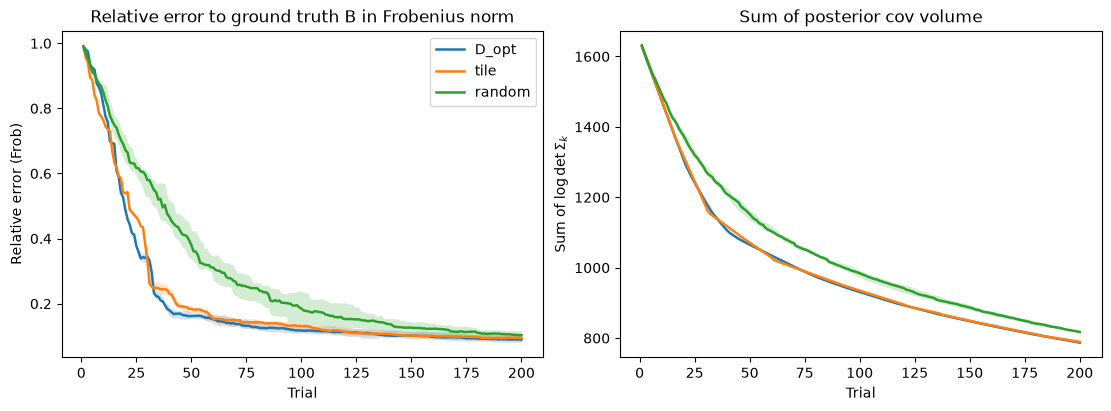

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
trials = np.arange(1, n_trials + 1)

for mode in ("D_opt", "tile", "random"):
    ld = logdet_curves[mode]
    print(f"{mode}: logdet drop {ld[:, 0].mean() - ld[:, -1].mean():.1f} nats, "
          f"final err {curves[mode][:, -1].mean():.4f}")
    for ax, data, ylab, logy in (
        (axes[0], curves[mode],        "Relative error (Frob)",             False),
        (axes[1], logdet_curves[mode], r"Sum of $\log\det \Sigma_k$", False),
    ):
        lo, med, hi = np.percentile(data, [25, 50, 75], axis=0)
        line = ax.plot(trials, med, lw=1.8, label=mode)[0]
        ax.fill_between(trials, lo, hi, color=line.get_color(), alpha=0.2, lw=0)
        ax.set_xlabel("Trial")
        ax.set_ylabel(ylab)
        if logy:
            ax.set_yscale("log")

axes[0].legend()
axes[0].set_title("Relative error to ground truth B in Frobenius norm")
axes[1].set_title("Sum of posterior cov volume")
plt.show()

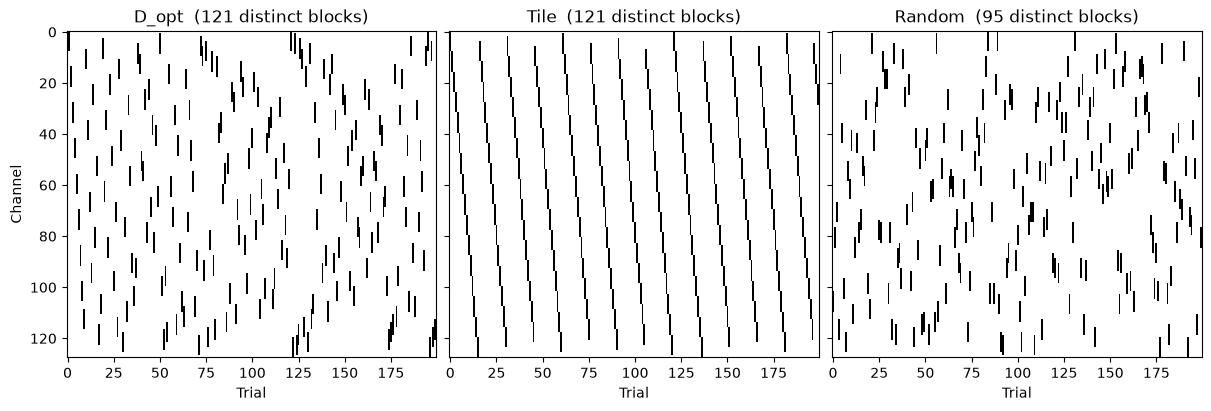

In [ ]:
seed_show = 0

fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True, sharey=True)

for ax, mode in zip(axes, ("D_opt", "tile", "random")):
    js = selections[mode][seed_show]

    S_sel = np.zeros((n_trials, N))
    for trial, j in enumerate(js):
        S_sel[trial, j:j + n_stim_ch] = 1.0

    ax.imshow(S_sel.T, aspect="auto", interpolation="nearest",
              vmin=0, vmax=1, cmap="Greys")
    ax.set_title(f"{mode.capitalize()}  ({len(np.unique(js))} distinct blocks)")
    ax.set_xlabel("Trial")

axes[0].set_ylabel("Channel")
plt.show()

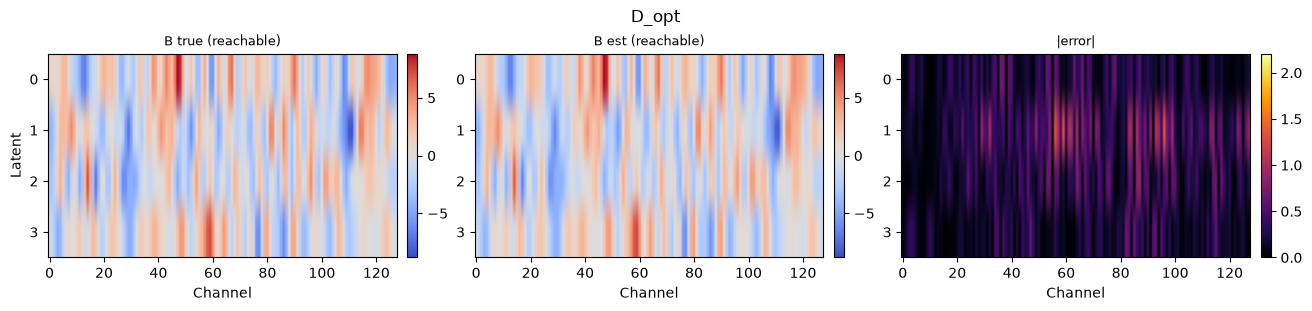

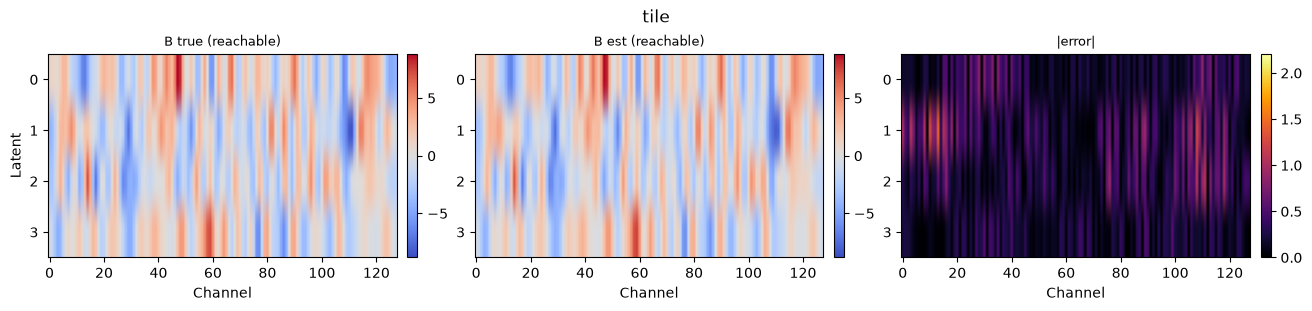

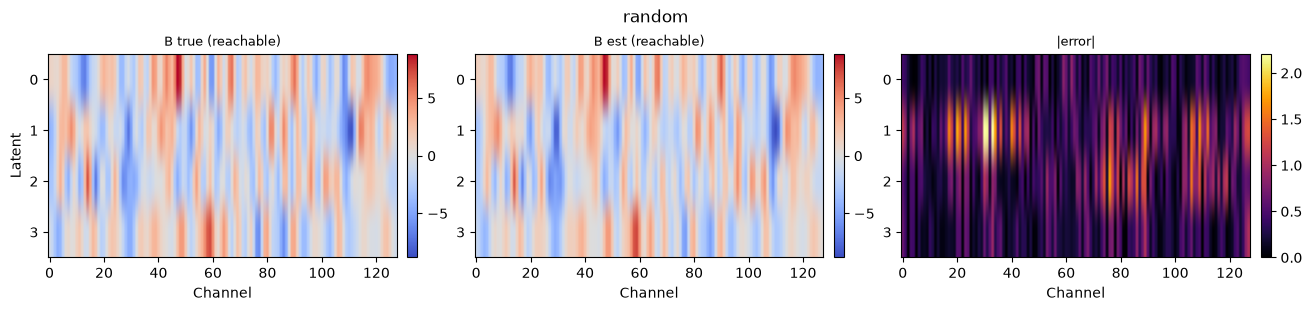

In [ ]:
def compare_B(W, B_ref, Pu, label=""):
    Wp, Bp = W @ Pu, B_ref @ Pu
    fig, axes = plt.subplots(1, 3, figsize=(13, 3), constrained_layout=True)
    lim = np.abs(Bp).max()
    for ax, (data, title, cmap, lo, hi) in zip(axes, [
        (Bp,      "B true (reachable)",  "coolwarm", -lim, lim),
        (Wp,      "B est (reachable)",   "coolwarm", -lim, lim),
        (np.abs(Wp - Bp), "|error|",     "inferno",   0,   lim/4),
    ]):
        im = ax.imshow(data, aspect="auto", cmap=cmap, vmin=lo, vmax=hi)
        ax.set_title(title, fontsize=9)
        ax.set_xlabel("Channel")
        fig.colorbar(im, ax=ax, pad=0.03)
    axes[0].set_ylabel("Latent")
    fig.suptitle(f"{label}")
    plt.show()

for mode in ("D_opt", "tile", "random"):
    *_, tracker, _ = run_selection(mode, n_trials, s_cand, B_true,
                               R_fixed, K, N, Pu, M_step, V, b, BETA_STIM, n_stim_ch=8)
    compare_B(tracker.W, B_true, Pu, label=mode)

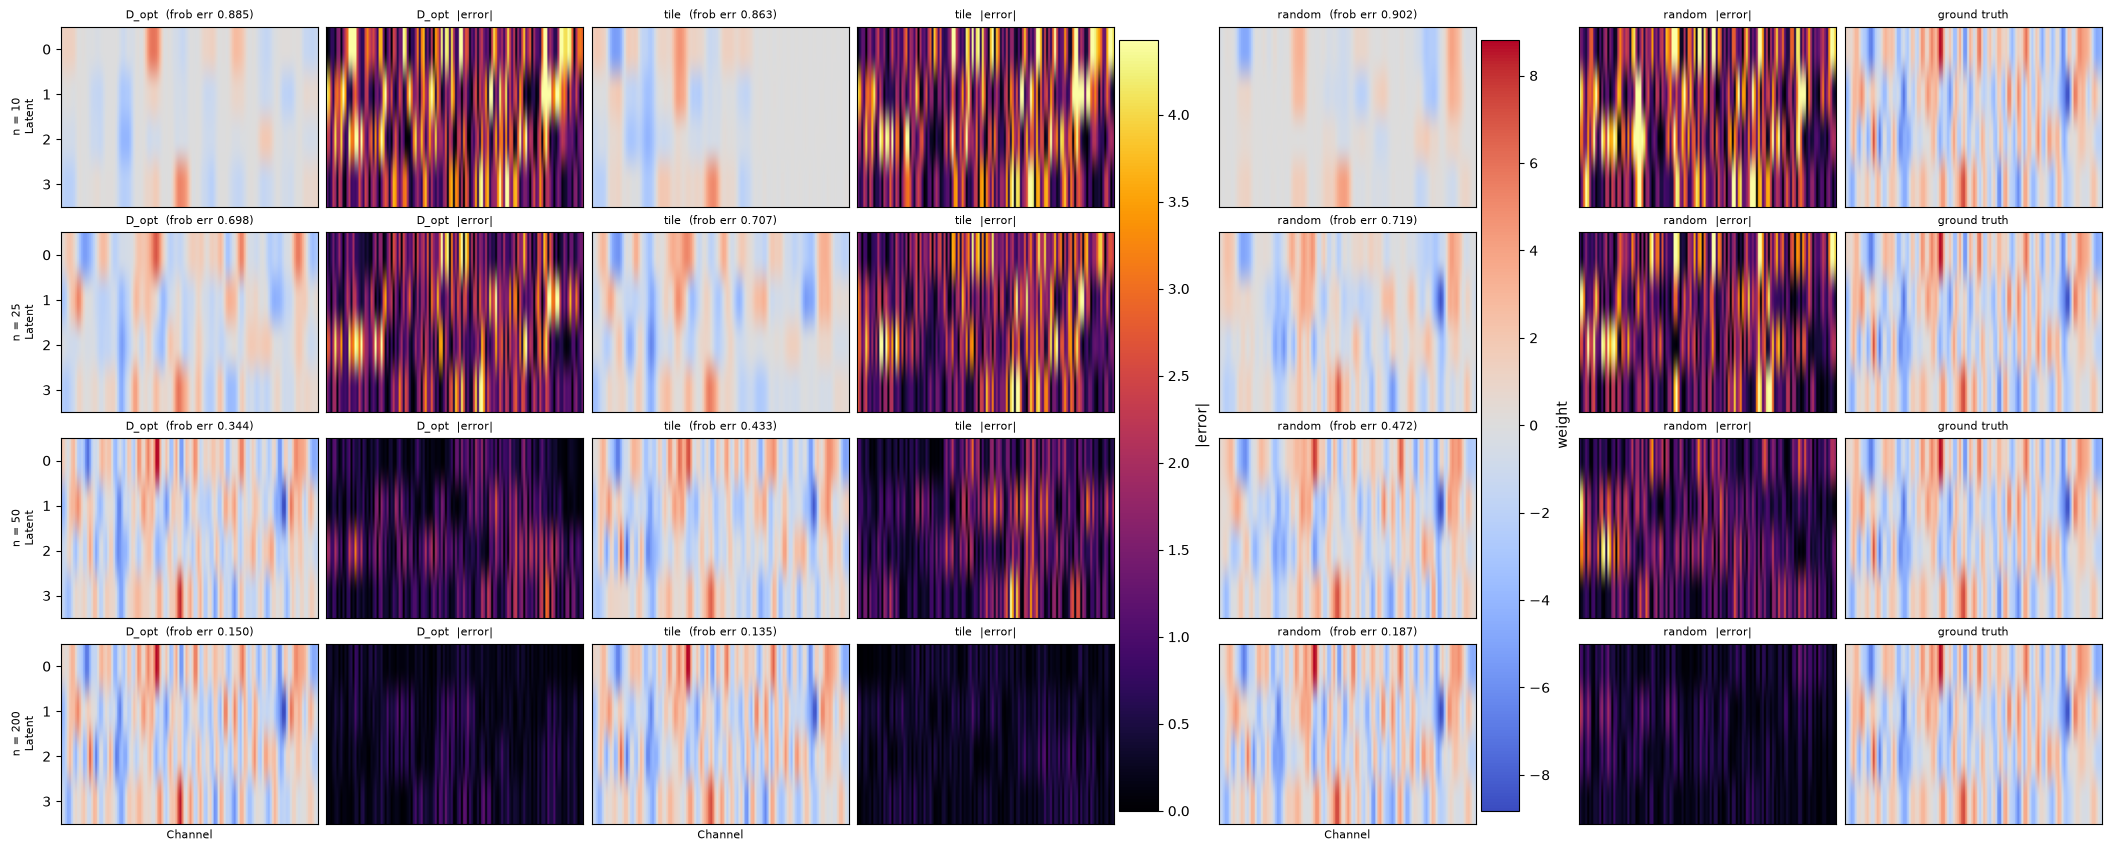

In [ ]:
snap_at = (10, 25, 50, 200)
modes = ("D_opt", "tile", "random")
snaps = {m: run_selection(m, 200, s_cand, B_true, R_fixed, K, N, Pu, M_step,
                          V, b, BETA_STIM, n_stim_ch=8, seed=0,
                          snap_at=snap_at)[4]
         for m in modes}

Bp = B_true @ Pu
lim = np.abs(Bp).max()
# Fix the error scale at the earliest snapshot so shrinkage across rows is visible
err_lim = max(np.abs(snaps[m][snap_at[0]] @ Pu - Bp).max()/2 for m in modes)

cols = [("D_opt", "W"), ("D_opt", "err"), ("tile", "W"), ("tile", "err"), ("random", "W"), ("random", "err"), (None, "gt")]
fig, axes = plt.subplots(len(snap_at), len(cols),
                         figsize=(3.0 * len(cols), 2.1 * len(snap_at)),
                         constrained_layout=True)
for r, n in enumerate(snap_at):
    for c, (mode, kind) in enumerate(cols):
        ax = axes[r, c]
        if kind == "gt":
            im_w = ax.imshow(Bp, aspect="auto", cmap="coolwarm", vmin=-lim, vmax=lim)
            title = "ground truth"
        else:
            Wp = snaps[mode][n] @ Pu
            if kind == "W":
                im_w = ax.imshow(Wp, aspect="auto", cmap="coolwarm", vmin=-lim, vmax=lim)
                rel = np.linalg.norm(Wp - Bp) / np.linalg.norm(Bp)
                title = f"{mode}  (frob err {rel:.3f})"
            else:
                im_e = ax.imshow(np.abs(Wp - Bp), aspect="auto", cmap="inferno",
                                 vmin=0, vmax=err_lim)
                title = f"{mode}  |error|"
        ax.set_title(title, fontsize=8)
        ax.set_xticks([])
        if c > 0:
            ax.set_yticks([])
    axes[r, 0].set_ylabel(f"n = {n}\nLatent", fontsize=8)

for c in (0, 2, 4):
    axes[-1, c].set_xlabel("Channel", fontsize=8)
fig.colorbar(im_w, ax=axes[:, 4], pad=0.02, label="weight")
fig.colorbar(im_e, ax=axes[:, 3], pad=0.02, label="|error|")
plt.show()

In [ ]:
# # Posterior calibration on the probed subspace
# RLS_tracker = RowRLS(K, N, prior_var=25.0)
# run_sequential(RLS_tracker, U, Z, R)
# zs = []
# for k in range(K):
#     for u in U[::7]:
#         var = u @ RLS_tracker.Sigma[k] @ u
#         zs.append(((RLS_tracker.W[k] - B_true[k]) @ u) / np.sqrt(max(var, 1e-12)))
# zs = np.array(zs)
# print(f"Calibration z-scores: mean {zs.mean():+.3f}, std {zs.std():.3f} (target 0, 1)")
# print("\n" + "=" * 60)
# print("Greedy channel selection from a cold prior")
# print("=" * 60)
# RLS_tracker = RowRLS(K, N, prior_var=25.0)
# s_sel, chosen, gain = select_stim_greedy(RLS_tracker, V, b, R_fixed, n_stim_ch, BETA_STIM)
# print(f"  channels: {sorted(chosen)}")
# print(f"  info gain: {gain:.3f} nats")
# print(f"  (compare best contiguous block: "
#         f"{max(RLS_tracker.info_gain(u, R_fixed) for u in U_cand):.3f} nats)")

# Q_fit = 0.2 * np.eye(state_dim)  # match dynamics_covariance to initialization
# U_real = effective_stim_input(np.asarray(S[:, t_stim, :]), np.asarray(params_GT["V"]), float(b_fit), BETA_STIM)

# # Get perturbation term from EKF/RTS smoother outputs
# Z_real, R_real = get_perturbation_agg(posts_fit.smoothed_means, posts_fit.smoothed_covariances, A_fit, Q_fit, t_stim - 1, t_stim)

# B_true_gt = np.asarray(params_GT["B"])  # ground truth in the original latent basis
# B_target = M_inv @ B_true_gt   # ground truth expressed in the fitted latent basis
# prior_var = float((B_target ** 2).mean())

# RLS_tracker = RowRLS(K, N, prior_var=prior_var)
# nis_real, logdet_real = run_sequential(RLS_tracker, U_real, Z_real, R_real)
# print(f"NIS {nis_real.mean():.2f} (target {K}), proj err "
#       f"{projected_error(RLS_tracker.W, B_target, U_real):.4f}")